# 06 - Unsupervised baselines on full HDFS

PCA and Isolation Forest on the block count vectors, trained only on normal blocks.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.models.unsupervised import IForestDetector, PCADetector, fit_and_score, threshold_sweep, time_split

DOCS = ROOT / "docs"
PERCENTILES = [90, 95, 97.5, 99, 99.5]

counts = pd.read_parquet(ROOT / "data" / "processed" / "hdfs_counts.parquet")
event_cols = [c for c in counts.columns if c.startswith("E")]

## Train / test split

The first 70% of blocks (by first appearance) are used for training, keeping only the normal ones, and the last 30% for testing.

In [2]:
train, test = time_split(counts, train_frac=0.7)
X_train = train.loc[train["Label"] == 0, event_cols].to_numpy()
X_test, y_test = test[event_cols].to_numpy(), test["Label"].to_numpy()

pd.DataFrame({
    "blocks": [len(train), len(X_train), len(test)],
    "anomalous blocks": [train["Label"].sum(), 0, y_test.sum()],
}, index=["first 70%", "train (normal only)", "test (last 30%)"])

,blocks,anomalous blocks
first 70%,402542,13115
train (normal only),389427,0
test (last 30%),172519,3723


## Train and score

PCA uses TF-IDF weighted, zero-mean counts and keeps 95% of the variance (He et al., 2016). Isolation Forest uses the raw counts.

In [3]:
models = {"PCA": PCADetector(variance=0.95), "Isolation Forest": IForestDetector(n_estimators=100, random_state=42)}
scores = {}
for name, model in models.items():
    train_scores, test_scores, fit_s, score_s = fit_and_score(model, X_train, X_test)
    scores[name] = (train_scores, test_scores)
    print(f"{name:17s} training: {fit_s:6.2f} s   scoring: {score_s:6.2f} s")

print(f"PCA components kept: {models['PCA'].pca.n_components_}")

PCA               training:   0.24 s   scoring:   0.44 s


Isolation Forest  training:   0.56 s   scoring:   1.29 s
PCA components kept: 4


## Score check

ROC-AUC of the raw test scores, where higher should mean more anomalous. An AUC below 0.5 would mean the score sign is reversed.

In [4]:
from sklearn.metrics import roc_auc_score

for name, (_, test_scores) in scores.items():
    print(f"{name:17s} ROC-AUC: {roc_auc_score(y_test, test_scores):.3f}")

if_test = scores["Isolation Forest"][1]
print(f"\nMean Isolation Forest score: normal {if_test[y_test == 0].mean():.4f}, anomalous {if_test[y_test == 1].mean():.4f}")

PCA               ROC-AUC: 0.961
Isolation Forest  ROC-AUC: 0.685

Mean Isolation Forest score: normal 0.4316, anomalous 0.4792


## Threshold test

Each threshold is a percentile of the model's scores on the normal training blocks. Many normal blocks have identical counts, so neighbouring percentiles can give the same threshold.

In [5]:
results = pd.DataFrame([
    row for name, (train_scores, test_scores) in scores.items()
    for row in threshold_sweep(name, train_scores, test_scores, y_test, PERCENTILES)
])

DOCS.mkdir(exist_ok=True)
results.round(4).to_csv(DOCS / "hdfs_unsupervised_results.csv", index=False)
results.style.format({c: "{:.3f}" for c in ["precision", "recall", "f1", "false_alarm_rate"]}).hide(axis="index")

model,percentile,precision,recall,f1,false_alarm_rate
PCA,90.000000,0.532,0.817,0.644,0.016
PCA,95.000000,0.532,0.817,0.644,0.016
PCA,97.500000,0.855,0.817,0.836,0.003
PCA,99.000000,0.860,0.817,0.838,0.003
PCA,99.500000,0.989,0.752,0.854,0.000
Isolation Forest,90.000000,0.059,0.045,0.051,0.016
Isolation Forest,95.000000,0.059,0.045,0.051,0.016
Isolation Forest,97.500000,0.009,0.006,0.007,0.016
Isolation Forest,99.000000,0.087,0.001,0.002,0.000
Isolation Forest,99.500000,0.087,0.001,0.002,0.000


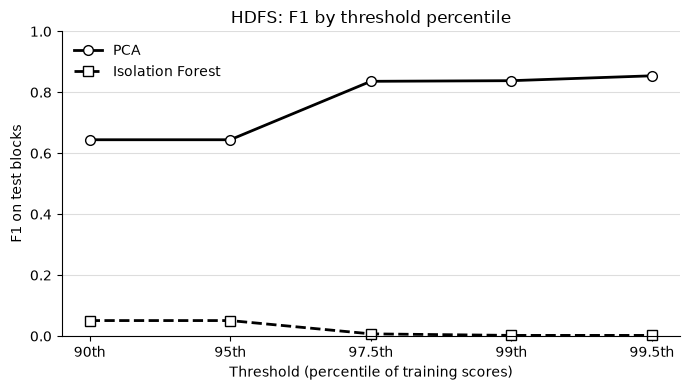

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(PERCENTILES))  # evenly spaced, since the percentiles are not
styles = {"PCA": dict(linestyle="-", marker="o"), "Isolation Forest": dict(linestyle="--", marker="s")}
for name, style in styles.items():
    f1 = results.loc[results["model"] == name, "f1"]
    ax.plot(x, f1, color="black", linewidth=2, markersize=7, markerfacecolor="white", clip_on=False, label=name, **style)

ax.set_xticks(x, [f"{p:g}th" for p in PERCENTILES])
ax.set_ylim(0, 1)
ax.set_xlabel("Threshold (percentile of training scores)")
ax.set_ylabel("F1 on test blocks")
ax.set_title("HDFS: F1 by threshold percentile")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color="#dddddd", linewidth=0.8)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(DOCS / "hdfs_unsupervised_f1.png", dpi=150, facecolor="white")
plt.show()